# Лабораторна робота №3
**Тема:** Застосування статистичних методів та засобів в задачах аналізу даних

## Завдання №1
Засвоїти використання методів математичної статистики за допомогою бібліотеки SciPy

In [16]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [17]:
%matplotlib inline

In [18]:
plt.style.use("ggplot")

In [19]:
# Розподіл Бернуллі
rv_bernoulli = stats.bernoulli(p=0.3)

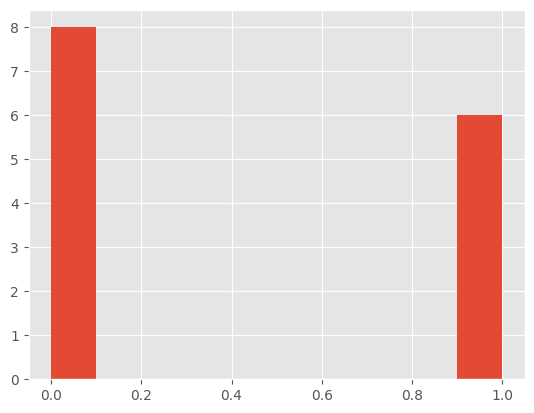

In [20]:
rv_bernoulli.rvs(14) # розмір вибірки
plt.hist(rv_bernoulli.rvs(14),bins=10)
plt.show;

In [21]:
# Біноміальний розподіл
rv_binom = stats.binom(100,p=0.9) # к-сть екпериментів і ймовірність

In [22]:
rv_binom.rvs(10) # згенерована вибірка

array([89, 91, 91, 89, 97, 96, 89, 91, 89, 91])

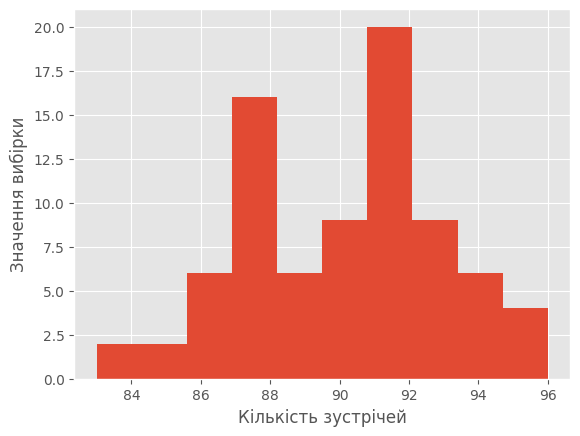

In [23]:
plt.hist(rv_binom.rvs(80), bins=10)
plt.xlabel("Кількість зустрічей")
plt.ylabel("Значення вибірки")
plt.show;

In [24]:
# Рівномірний розподіл
a = 5 # старт
b = 10 # зміщення

In [25]:
rv_uniform = stats.uniform(a, b - a) # обʼєкт випадкової величини

In [26]:
rv_uniform.cdf(5.5) # функція розподілу в певній точці

np.float64(0.1)

In [27]:
rv_uniform.pdf(7) # густина імовірності

np.float64(0.2)

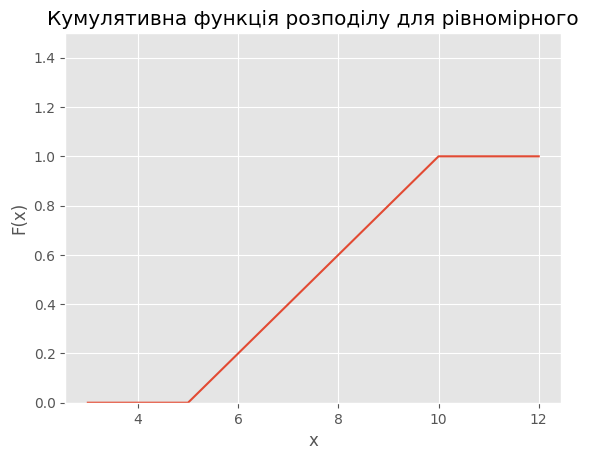

In [28]:
# Графік функціонального розподілу
X = np.linspace(a-2, b+2, 100)
cdf = rv_uniform.cdf(X)
plt.plot(X,cdf)
plt.ylabel("F(x)")
plt.xlabel("x")
plt.ylim([0,1.5])
plt.title("Кумулятивна функція розподілу для рівномірного")
plt.show();

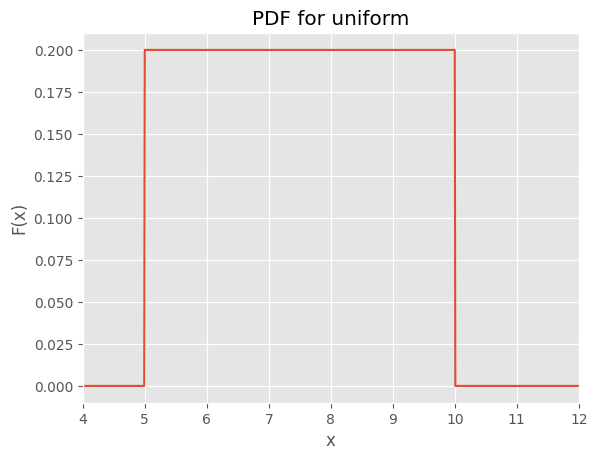

In [29]:
# Графік густини ймовірності
X = np.linspace(a-2, b+2, 1000)
pdf = rv_uniform.pdf(X)
plt.plot(X,pdf)
plt.ylabel("F(x)")
plt.xlabel("x")
plt.xlim([4, 12])
plt.title("PDF for uniform")
plt.show();

In [30]:
# Нормальний розподіл
mu = 2 # середнє значення
sigma = 0.5 # сигма

In [31]:
rv_norm = stats.norm(loc=mu, scale=sigma)

In [32]:
rv_norm.rvs(17) # sample даних

array([1.92995454, 2.6115758 , 2.18357631, 2.09302343, 1.51788902,
       1.94520698, 2.0627574 , 2.17452584, 1.9958373 , 1.52321332,
       1.73951993, 2.15250204, 2.66424404, 1.69020731, 2.59260297,
       1.72566516, 1.72161059])

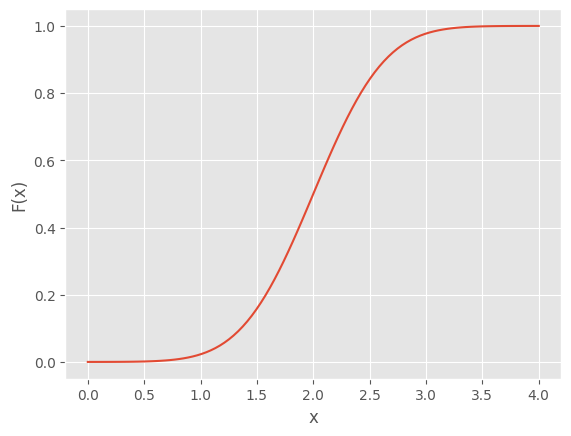

In [33]:
# Графік функції розпооділу
x = np.linspace(0,4,100)
cdf = rv_norm.cdf(x)
plt.plot(x, cdf)
plt.ylabel("F(x)")
plt.xlabel("x")
plt.show;


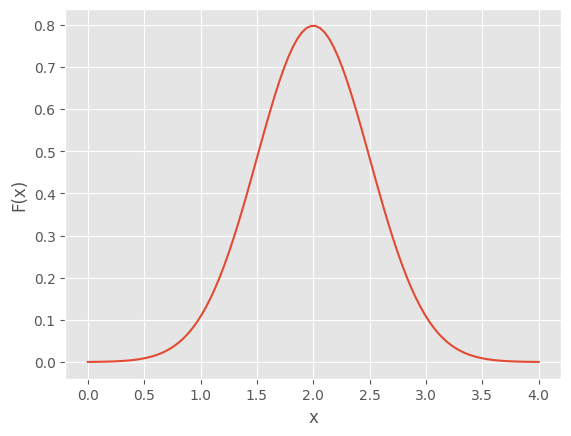

In [34]:
# Графік густини ймовірності
x = np.linspace(0,4,100)
pdf = rv_norm.pdf(x)
plt.plot(x,pdf)
plt.ylabel("F(x)")
plt.xlabel("x")
plt.show;

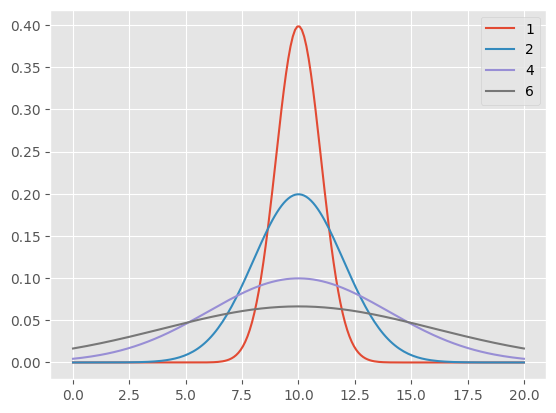

In [35]:
means = [1,5,10]
mu = 10
sigmas = [1,2,4,6]
for sigma in sigmas:
    rv_norm = stats.norm(loc=mu, scale=sigma)
    x = np.linspace(0,20,200)
    pdf = rv_norm.pdf(x)
    plt.plot(x,pdf, label = sigma)
plt.legend();

## Завдання №2
Із датасетом виконати усі операції для отримання довірчого інтервалу

In [36]:
import pandas as pd

In [37]:
h_price = pd.read_csv("Housing_price_Data.csv")

In [38]:
h_price.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning
0,13300000,7420,4,2,3,yes,no,no,no,yes
1,12250000,8960,4,4,4,yes,no,no,no,yes
2,12250000,9960,3,2,2,yes,no,yes,no,no
3,12215000,7500,4,2,2,yes,no,yes,no,yes
4,11410000,7420,4,1,2,yes,yes,yes,no,yes


In [39]:
data_column = h_price['price'] # Колонка для якої будемо шукати довірчий інтервал

In [61]:
# Випадкова вибірка з поверненням

def generate_distribution_sample(data, sample_size, dist_size):
    sample_means = []
    for i in range(dist_size):
        sample = np.random.choice(a=data, size=sample_size)
        sample_means.append(np.mean(sample))
    return sample_means

In [62]:
# Задаємо розмір однієї вибірки та кількість симуляцій
sample_size = 300
dist_size = 20000

In [63]:
# Генеруємо розподіл середніх значень
sample_means = generate_distribution_sample(
    data_column, sample_size, dist_size
)

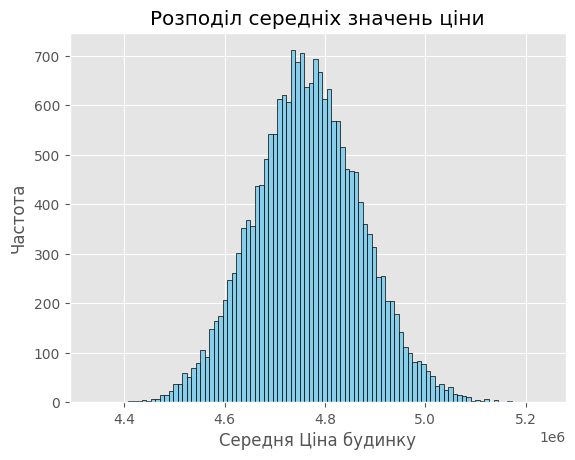

In [64]:
plt.hist(sample_means, bins=100, color='skyblue', edgecolor='black')
plt.xlabel('Середня Ціна будинку')
plt.ylabel('Частота')
plt.title('Розподіл середніх значень ціни')
plt.show()

In [66]:
# Обчислення довірчого інтервалу
sorted_means = np.sort(sample_means)
lb = np.percentile(sorted_means, 2.5) # Нижня межа
ub = np.percentile(sorted_means, 97.5) # Верхня межа

In [67]:
print(
    f'95% довірчий інтервал для середньої ціни: '
    f'({lb:,.2f}, {ub:,.2f})'
)

95% довірчий інтервал для середньої ціни: (4,558,176.03, 4,982,813.73)


## Завдання №3
Виконати перевірку гіпотез і розподіл Стьюдента

In [70]:
# Беремо вибірку цін (300 випадкових будинків)
sample_price = h_price['price'].sample(n=300, random_state=42)

In [71]:
# Перевіряємо одновибірний t-критерій
t_stat, p_value = stats.ttest_1samp(sample_price, 4800000)

In [74]:
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value}')

t-статистика: 0.7976
p-value: 0.42574100409632853


In [75]:
# Вибірка 1: будинки з кондиціонером ('yes')
prices_with_ac = h_price[h_price['airconditioning'] == 'yes']['price'].sample(
    n=150, random_state=42
)

In [76]:
# Вибірка 2: будинки без кондиціонера ('no')
prices_without_ac = h_price[h_price['airconditioning'] == 'no']['price'].sample(
    n=150, random_state=42
)

In [77]:
# Застосовуємо ttest_ind
t_stat, p_value = stats.ttest_ind(prices_with_ac, prices_without_ac)

print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value}')

t-статистика: 8.4460
p-value: 1.3431357966636433e-15


In [82]:
# Формуємо дві вибірки однакового розміру (по 100 елементів) за допомогою наявної колонки 'basement'
group_yes = h_price[h_price['basement'] == 'yes']['price'].sample(
    n=100, random_state=42
)
group_no = h_price[h_price['basement'] == 'no']['price'].sample(
    n=100, random_state=42
)

In [83]:
# Застосовуємо ttest_rel через .values (як у твоїй методичці для демонстрації)
t_stat, p_value = stats.ttest_rel(group_yes.values, group_no.values)

print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value}')

t-статистика: 2.7845
p-value: 0.0064236290879278474
